In [2]:
# Initialisation

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import umap

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

SEED = 0
SAMPLES_PER_CLASS = 500
CLASS_IDS = list(range(10))

np.random.seed(SEED)
torch.manual_seed(SEED)

/home/kleinq/Documents/M1/DLCV/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 9.91M/9.91M [00:01<00:00, 7.97MB/s]
100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 28.9k/28.9k [00:00<00:00, 334kB/s]
100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1.65M/1.65M [00:00<00:00, 3.17MB/s]
100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 4.54k/4.54k [00:00<00:00, 6.49MB/s]


MNIST: (5000, 784)


/home/kleinq/Documents/M1/DLCV/.venv/lib/python3.11/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/home/kleinq/Documents/M1/DLCV/.venv/lib/python3.11/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


MNIST embedding: (5000, 2)


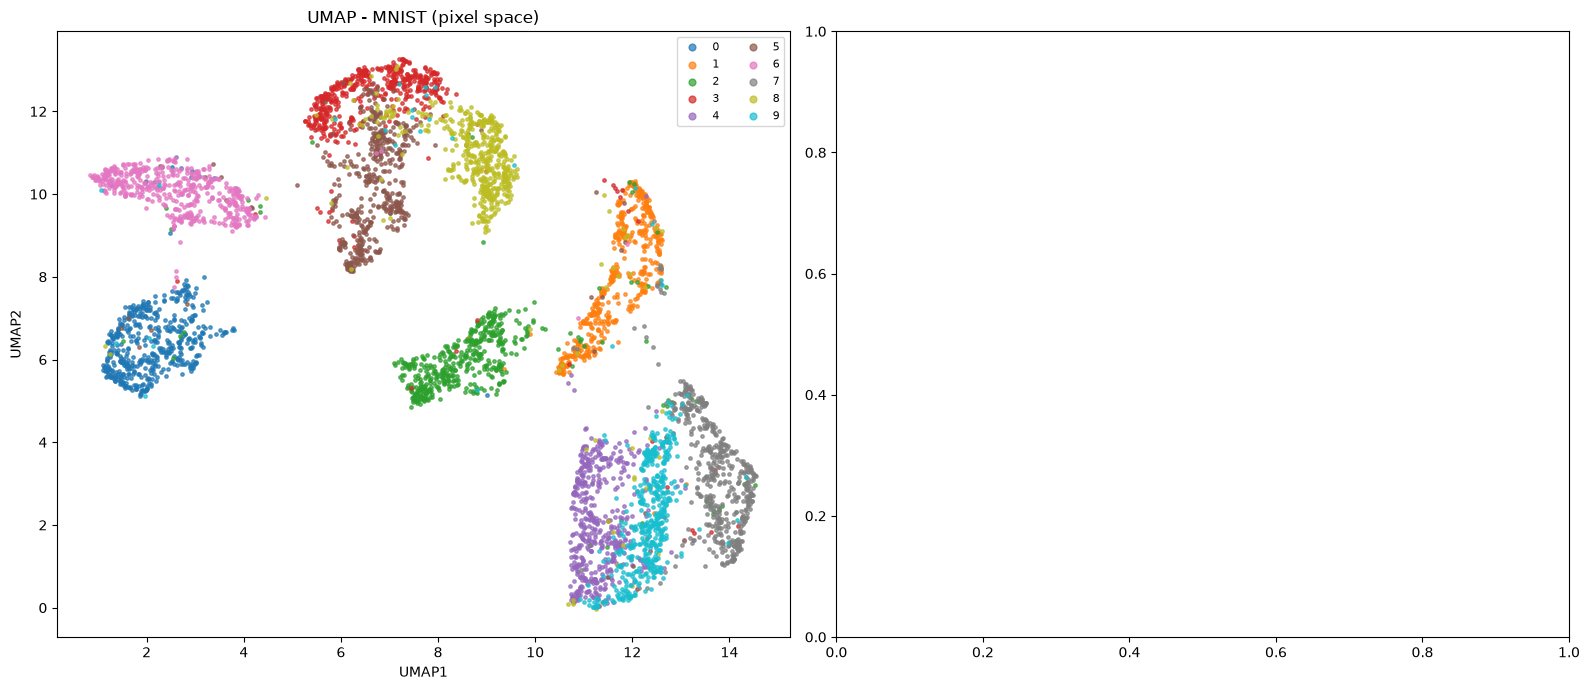

In [3]:
# Experiment 0

mnist = datasets.MNIST(root="./data", train=True, download=True, transform=transforms.ToTensor())
"""
imagenet_transform = transforms.Compose([
  transforms.Resize((64,64)),
  transforms.ToTensor()
])
imagenet = datasets.ImageNet(root="/path/to/imagenet", split="train", transform=imagenet_transform)
"""

def balanced_subset(dataset, class_ids, n_per_class=500, seed=0):
  rng = np.random.default_rng(seed)
  targets = np.asarray(dataset.targets)
  selected_indices = []
  for class_id in class_ids:
    candidates = np.flatnonzero(targets == class_id)
    if len(candidates) < n_per_class:
      raise ValueError(f"Class {class_id} has only {len(candidates)} images.")
    indices = rng.choice(candidates, size=n_per_class, replace=False)
    selected_indices.extend(indices.tolist())
  rng.shuffle(selected_indices)
  return Subset(dataset, selected_indices)

mnist_subset = balanced_subset(mnist, CLASS_IDS, SAMPLES_PER_CLASS, SEED)

# imagenet_subset = balanced_subset(imagenet, CLASS_IDS, SAMPLES_PER_CLASS, SEED)

def extract_pixels(dataset, batch_size=128):
  loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=0)
  features=[]
  labels=[]
  for images, targets in loader:
    flattened = images.flatten(start_dim=1)
    features.append(flattened.numpy())
    labels.append(targets.numpy())
  X = np.concatenate(features, axis=0).astype(np.float32)
  y = np.concatenate(labels, axis=0)
  return X, y

X_mnist, y_mnist = extract_pixels(mnist_subset)
# X_imagenet, y_imagenet = extract_pixels(imagenet_subset)

print("MNIST:", X_mnist.shape)
# print("ImageNet:", X_imagenet.shape)

def run_umap(X, n_neighbors=15, min_dist=0.1, seed=0):
  reducer = umap.UMAP(n_neighbors=n_neighbors, min_dist=min_dist, n_components=2, metric="euclidean", random_state=seed, low_memory=True)
  embedding = reducer.fit_transform(X)
  return embedding

embedding_mnist = run_umap(X_mnist)
# embedding_imagenet = run_umap(X_imagenet)
print("MNIST embedding:", embedding_mnist.shape)
# print("ImageNet embedding:", embedding_imagenet.shape)

def plot_umap(embedding, labels, class_names, title, ax):
  colors = plt.get_cmap("tab10")
  for class_id in np.unique(labels):
    mask = labels == class_id
    ax.scatter(embedding[mask, 0], embedding[mask, 1], color=colors(int(class_id)), label=class_names[int(class_id)], s=6, alpha=0.7, rasterized=True)
  ax.set_title(title)
  ax.set_xlabel("UMAP1")
  ax.set_ylabel("UMAP2")
  ax.legend(markerscale=2, fontsize=8, ncol=2)

mnist_names = [str(i) for i in range(10)]
# imagenet_names = [name[0] is isinstance(name, (tuple, list)) else name for name in imagenet.classes[:10]]
fig, axes = plt.subplots(1, 2, figsize=(16,7))
plot_umap(embedding_mnist, y_mnist, mnist_names, "UMAP - MNIST (pixel space)", axes[0])
# plot_umap(embedding_imagenet, y_imagenet, imagenet_names, "UMAP - ImageNet (pixel space)", axes[1])
plt.tight_layout()
plt.savefig("umap_pixel_space.png", dpi=200, bbox_inches="tight")
plt.show()

# Expérience 0

En projetant les données MNIST d'entraînement avec UMAP, on peut observer que la plupart des classes sont déjà bien séparées: on peut supposer que le jeu de données possède une certaine structure dans le domaine des pixels. Cependant, certaines classes sont tout de même très proches (3, 5 et 8, et 4, 9 et 7): la projection UMAP ne classifiant pas, elle préserve simplement les relations de voisinage dans les données. C'est particulièrement visible pour 3, 5, et 8 qui, manuscrits, peuvent être assez similaires visuellement. On ne peut donc pas tirer une conclusion véritablement sémantique de UMAP.

(TODO: ImageNet)

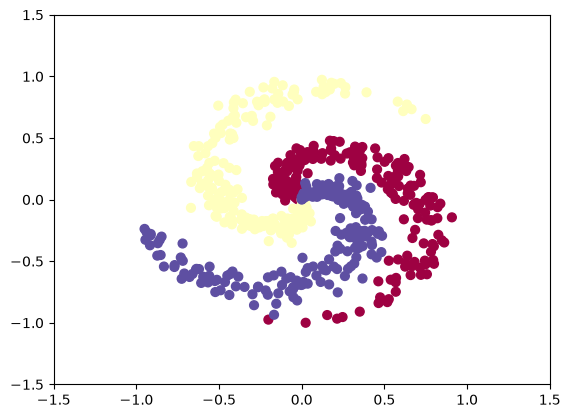

Final: (4000, 0.04211672767996788, 0.9895833730697632, 0.9666666984558105)


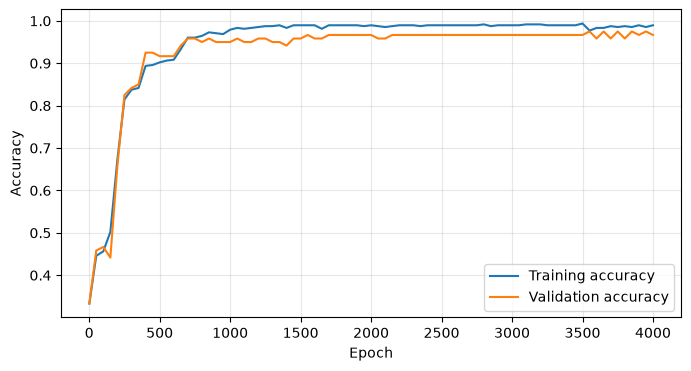

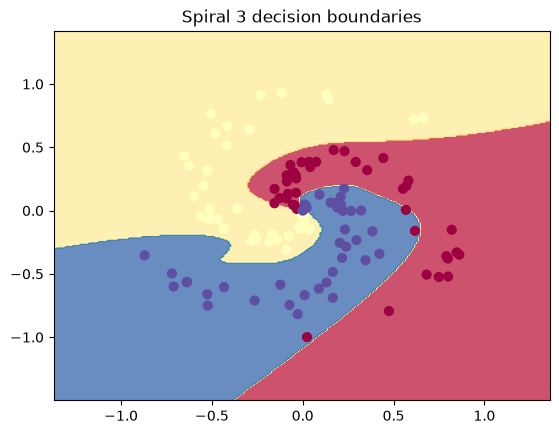

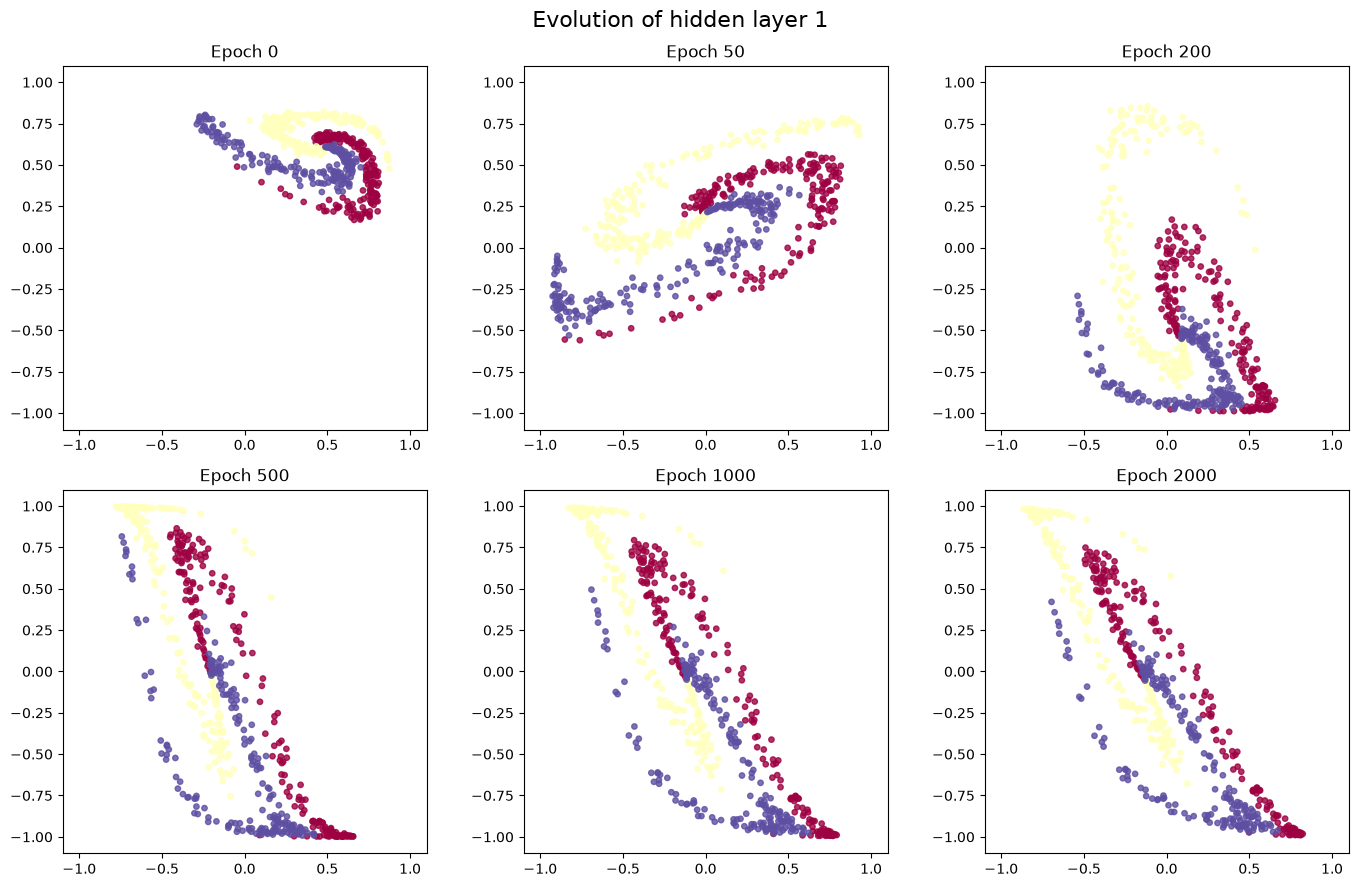

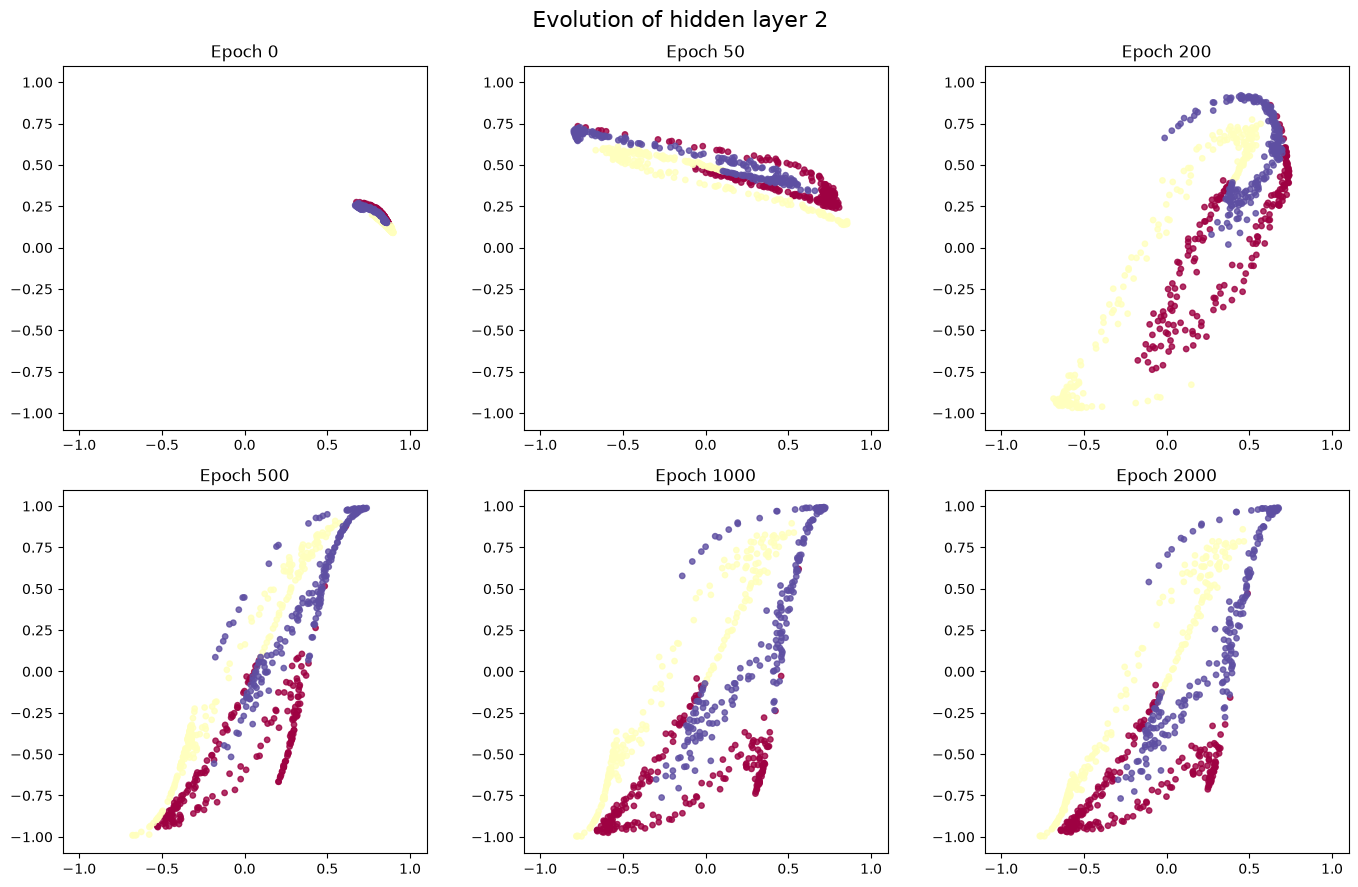

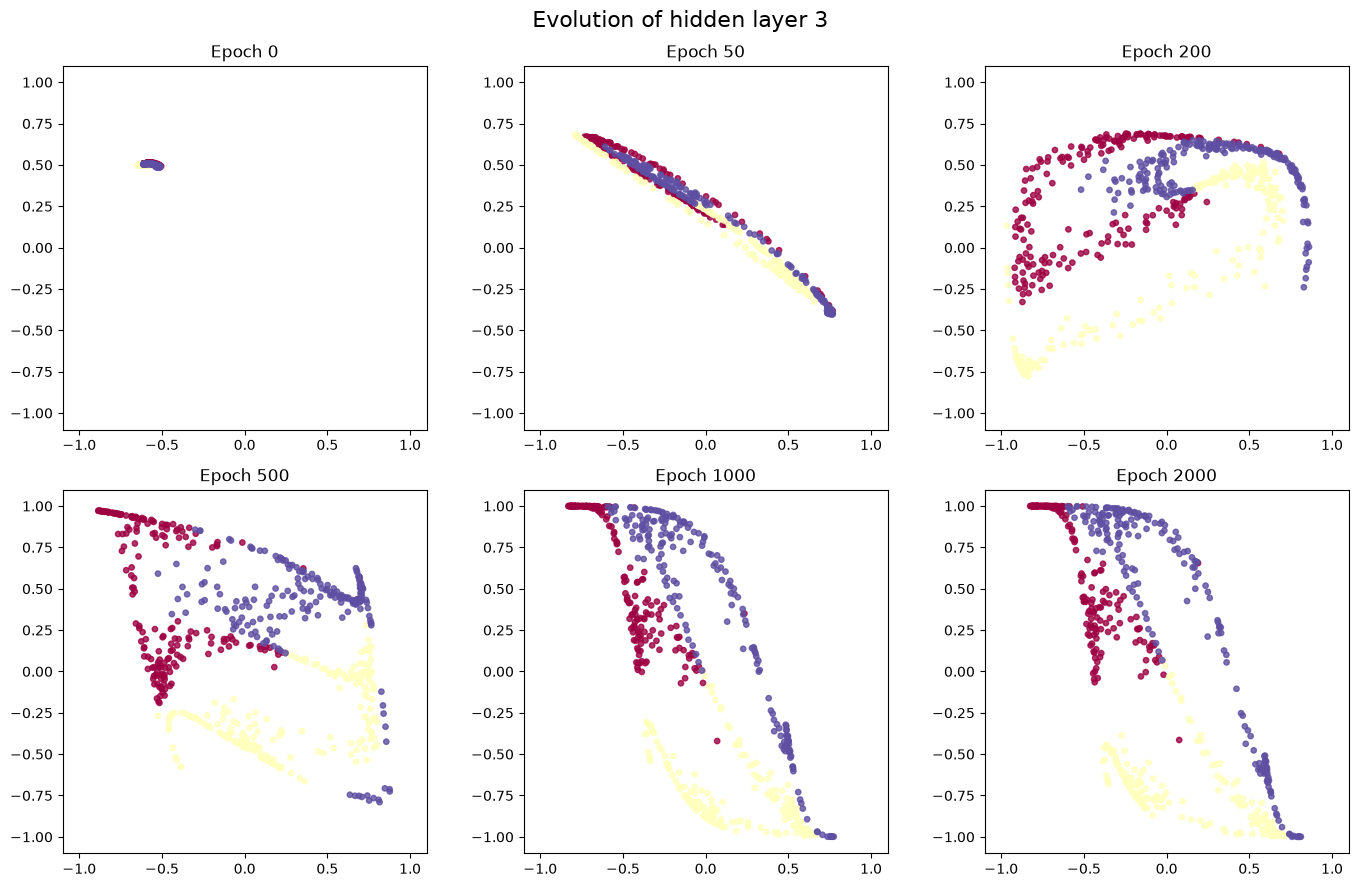

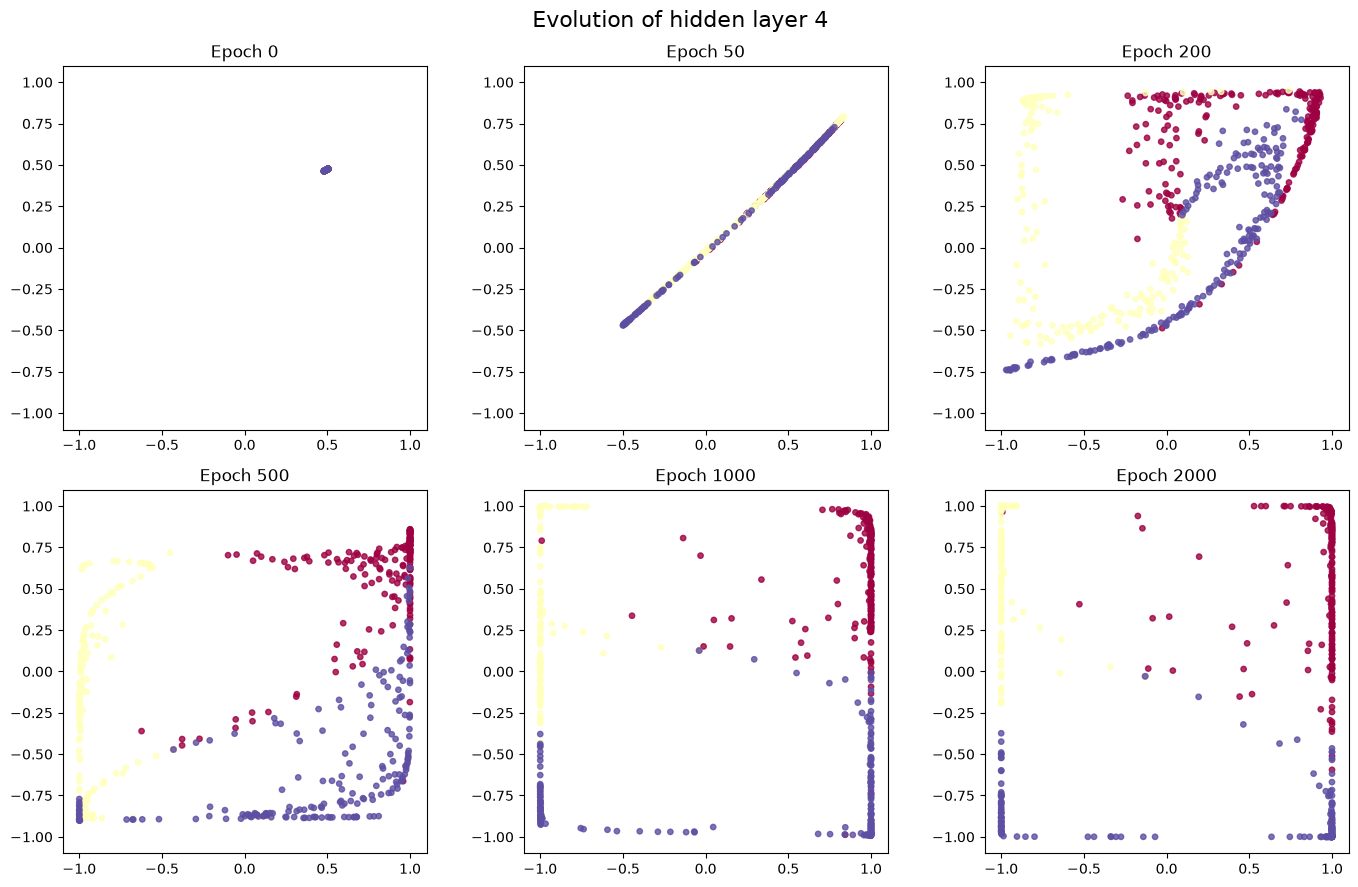

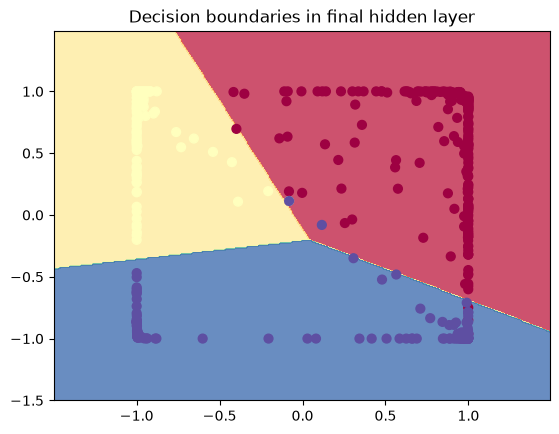

In [9]:
# Experiment 1

def toy_spiral3(N=200, K=3, D=2):
    # N points per class, D dimensions, K classes, arranged as three interleaved arms
    np.random.seed(0)
    X = np.zeros((N * K, D))
    y = np.zeros(N * K, dtype='uint8')
    for j in range(K):
        ix = range(N * j, N * (j + 1))
        r = np.linspace(0.0, 1, N)                                    # radius
        t = 5 + np.linspace(j * 4, (j + 1) * 4, N) + np.random.randn(N) * 0.3   # angle
        X[ix] = np.c_[r * np.sin(t), r * np.cos(t)]
        y[ix] = j
    return X, y


def toy_plot(X, y):
    plt.figure()
    plt.scatter(X[:, 0], X[:, 1], c=y, s=40, cmap=plt.cm.Spectral)
    plt.xlim([-1.5, 1.5])
    plt.ylim([-1.5, 1.5])


def plot_decision_boundaries(X, y, f, title=""):
    h = 0.01
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
    Z = f(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    plt.figure()
    plt.contourf(xx, yy, Z, cmap=plt.cm.Spectral, alpha=0.8)
    plt.scatter(X[:, 0], X[:, 1], c=y, s=40, cmap=plt.cm.Spectral)
    plt.xlim(xx.min(), xx.max())
    plt.ylim(yy.min(), yy.max())
    plt.title(title)
    plt.show()

# Generate spiral
X, y = toy_spiral3()
# 80/20 training-validation split
rng = np.random.default_rng(SEED)
train_idx, val_idx = [], []
for c in np.unique(y):
  indices = rng.permutation(np.flatnonzero(y == c))
  cut = int(0.8 * len(indices))
  train_idx.extend(indices[:cut])
  val_idx.extend(indices[cut:])
X_train = torch.tensor(X[train_idx], dtype=torch.float32, device=device)
y_train = torch.tensor(y[train_idx], dtype=torch.long, device=device)
X_val = torch.tensor(X[val_idx], dtype=torch.float32, device=device)
y_val = torch.tensor(y[val_idx], dtype=torch.long, device=device)
toy_plot(X, y)
plt.show()

class SpiralNet(nn.Module):
  def __init__(self, n_hidden=3):
    super().__init__()
    self.hidden = nn.ModuleList()
    for _ in range(n_hidden):
      self.hidden.append(nn.Sequential(nn.Linear(2, 2), nn.Tanh()))
    self.output = nn.Linear(2, 3)

  def project(self, x, layer_index):
    """
    layer_index = 0: original input
    layer_index = 1: first hidden layer
    layer_index = 2: second hidden layer
    etc.
    """
    if not 0 <= layer_index <= len(self.hidden):
      raise ValueError("Invalid layer index")
    for layer in self.hidden[:layer_index]:
      x = layer(x)
    return x

  def forward(self, x):
    x = self.project(x, len(self.hidden))
    return self.output(x)

N_HIDDEN = 4
EPOCHS = 4000
LEARNING_RATE = 0.01
WEIGHT_DECAY = 1e-5

CHECKPOINTS= [0, 50, 200, 500, 1000, 2000]
model = SpiralNet(n_hidden=N_HIDDEN).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

def save_state(model):
  return {name: value.detach().cpu().clone() for name, value in model.state_dict().items()}

states = {0: save_state(model)}
history = []
for epoch in range(1, EPOCHS + 1):
  model.train()
  optimizer.zero_grad()
  logits = model(X_train)
  loss = criterion(logits, y_train)
  loss.backward()
  optimizer.step()
  if epoch in CHECKPOINTS:
    states[epoch] = save_state(model)
  if epoch % 50 == 0 or epoch == 1:
    model.eval()
    with torch.no_grad():
      train_acc = ((model(X_train).argmax(dim=1) == y_train).float().mean().item())
      val_acc = ((model(X_val).argmax(dim=1) == y_val).float().mean().item())
    history.append((epoch, loss.item(), train_acc, val_acc))
print("Final:", history[-1])

# CHeck training performance
history_array = np.array(history)
plt.figure(figsize=(8,4))
plt.plot(history_array[:, 0], history_array[:, 2], label="Training accuracy")
plt.plot(history_array[:, 0], history_array[:, 3], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

def predict_classes(X_numpy):
  model.eval()
  with torch.no_grad():
    inputs = torch.tensor(X_numpy, dtype=torch.float32, device=device)
    logits = model(inputs)
    predictions = logits.argmax(dim=1)
  return predictions.cpu().numpy()

plot_decision_boundaries(X[val_idx], y[val_idx], predict_classes, title="Spiral 3 decision boundaries")

X_all = torch.tensor(X, dtype=torch.float32, device=device)
view_model = SpiralNet(n_hidden=N_HIDDEN).to(device)
# Visualize the evolution of each hidden layer
for VIS_LAYER in range (1, N_HIDDEN + 1):
    fig, axes = plt.subplots(2, 3, figsize=(14,9))
    # One subplot for each saved epoch
    for ax, (epoch, weights) in zip(axes.flat, sorted(states.items())):
        view_model.load_state_dict(weights)
        view_model.eval()
        with torch.no_grad():
            projection = view_model.project(X_all, VIS_LAYER).cpu().numpy()
        ax.scatter(projection[:, 0], projection[:, 1], c=y, cmap=plt.cm.Spectral, vmin=0, vmax=2, s=15, alpha=0.8)
        ax.set_xlim(-1.1, 1.1)
        ax.set_ylim(-1.1, 1.1)
        ax.set_aspect("equal", adjustable="box")
        ax.set_title(f"Epoch {epoch}")
    fig.suptitle(f"Evolution of hidden layer {VIS_LAYER}", fontsize=16)
    fig.tight_layout()
    plt.show()

model.eval()
with torch.no_grad():
  H = model.project(X_all, N_HIDDEN).cpu().numpy()

def predict_in_hidden_space(H_numpy):
  with torch.no_grad():
    h = torch.tensor(H_numpy, dtype=torch.float32, device=device)
    logits = model.output(h)
    return logits.argmax(dim=1).cpu().numpy()

plot_decision_boundaries(H, y, predict_in_hidden_space, title="Decision boundaries in final hidden layer")

# Expérience 1

En utilisant UMAP, nous pouvons observer l'évolution de la représentation apprise à chaque couche, et l'évolution de la dernière couche (ici, la quatrième) est particulièrement intéressante: on peut voir que la projection des points tend vers une représentation mieux linéairement séparable des points. En fonction de comment le modèle apprend, on peut même se retrouver avec une division 1/3 - 1/3 - 1/3 du plan pour chaque classe.

On utilise deux neurones par couche car cela produit une représentation qui est déjà en deux dimensions, et donc plus simple à visualiser. On aurait également pu utiliser UMAP si chaque couche possèdait plus de deux neurones, mais cette configuration facilite la visualisation.

Random   | Epoch 00 |train loss 2.9869, acc 9.83% |val loss 2.9851, acc 10.15%
Random   | Epoch 01 |train loss 0.1741, acc 94.31% |val loss 0.1740, acc 94.45%
Random   | Epoch 02 |train loss 0.1115, acc 96.64% |val loss 0.1244, acc 96.65%
Random   | Epoch 03 |train loss 0.0639, acc 98.08% |val loss 0.1120, acc 96.60%
Random   | Epoch 04 |train loss 0.0352, acc 98.93% |val loss 0.0549, acc 97.90%
Random   | Epoch 05 |train loss 0.0215, acc 99.25% |val loss 0.0593, acc 98.15%
Random   | Epoch 06 |train loss 0.0110, acc 99.71% |val loss 0.0390, acc 98.90%
Random   | Epoch 07 |train loss 0.0164, acc 99.48% |val loss 0.0367, acc 98.70%
Random   | Epoch 08 |train loss 0.0353, acc 98.80% |val loss 0.0680, acc 98.00%
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /home/kleinq/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|███████████████████████████████████████████████████████████████████████████████████████████████| 44.7M/44.7M [00:04<00:00, 11.5MB/s]


ImageNet | Epoch 00 |train loss 2.3889, acc 8.97% |val loss 2.3871, acc 9.30%
ImageNet | Epoch 01 |train loss 0.0637, acc 98.03% |val loss 0.0622, acc 98.10%
ImageNet | Epoch 02 |train loss 0.0413, acc 98.82% |val loss 0.0626, acc 98.45%
ImageNet | Epoch 03 |train loss 0.0281, acc 99.20% |val loss 0.0511, acc 98.45%
ImageNet | Epoch 04 |train loss 0.0558, acc 98.31% |val loss 0.0727, acc 97.85%
ImageNet | Epoch 05 |train loss 0.0177, acc 99.48% |val loss 0.0444, acc 98.65%
ImageNet | Epoch 06 |train loss 0.0114, acc 99.68% |val loss 0.0373, acc 99.00%
ImageNet | Epoch 07 |train loss 0.0248, acc 99.27% |val loss 0.0497, acc 98.50%
ImageNet | Epoch 08 |train loss 0.0045, acc 99.83% |val loss 0.0324, acc 99.40%


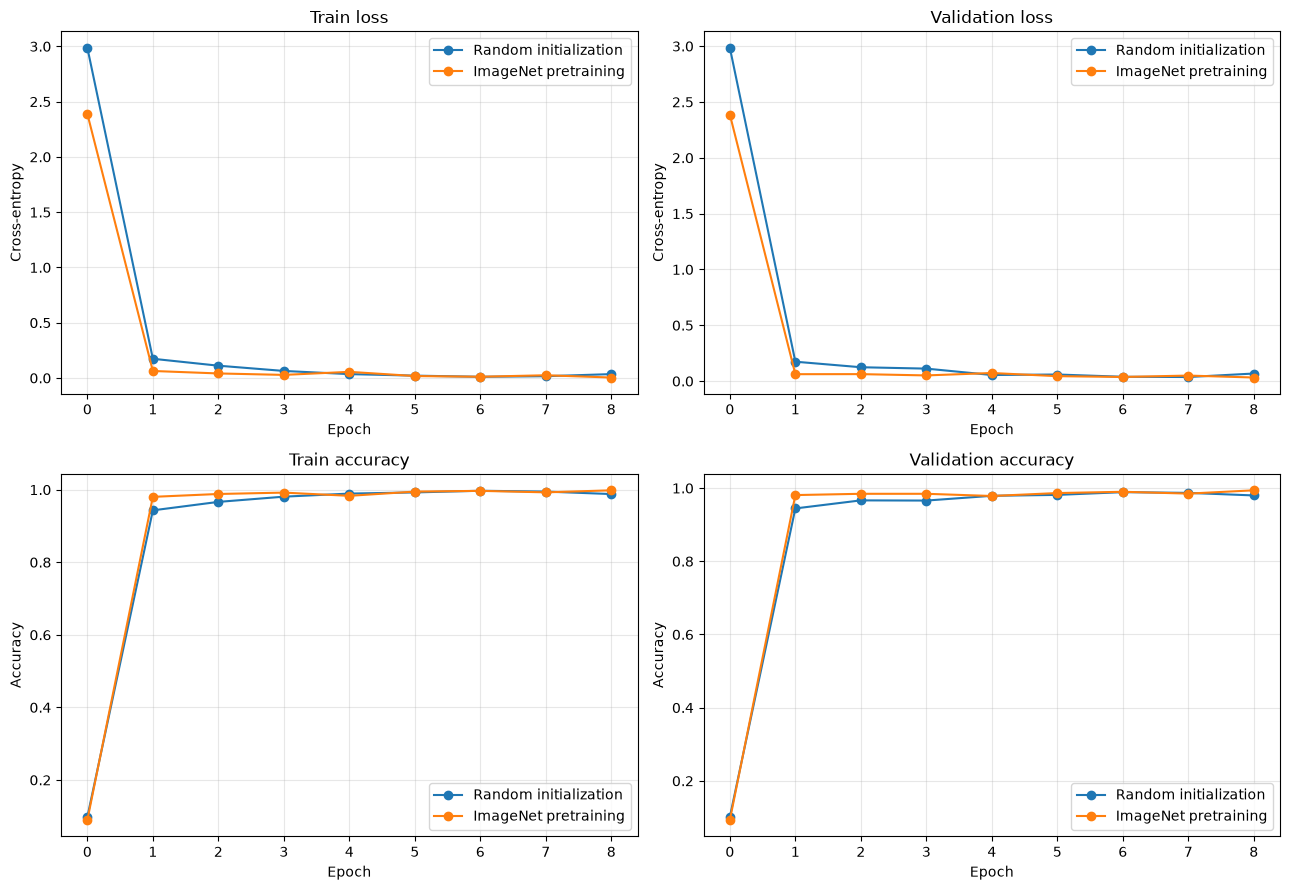

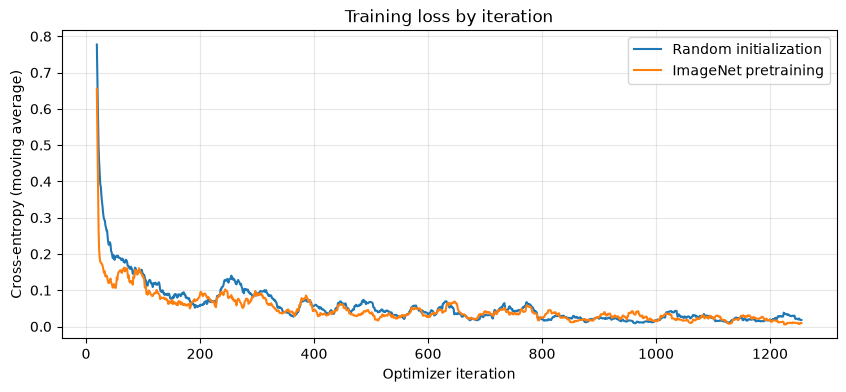

Features before flatten: (2000, 512) (2000, 512)


/home/kleinq/Documents/M1/DLCV/.venv/lib/python3.11/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/home/kleinq/Documents/M1/DLCV/.venv/lib/python3.11/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/kleinq/Documents/M1/DLCV/.venv/lib/python3.11/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initializa

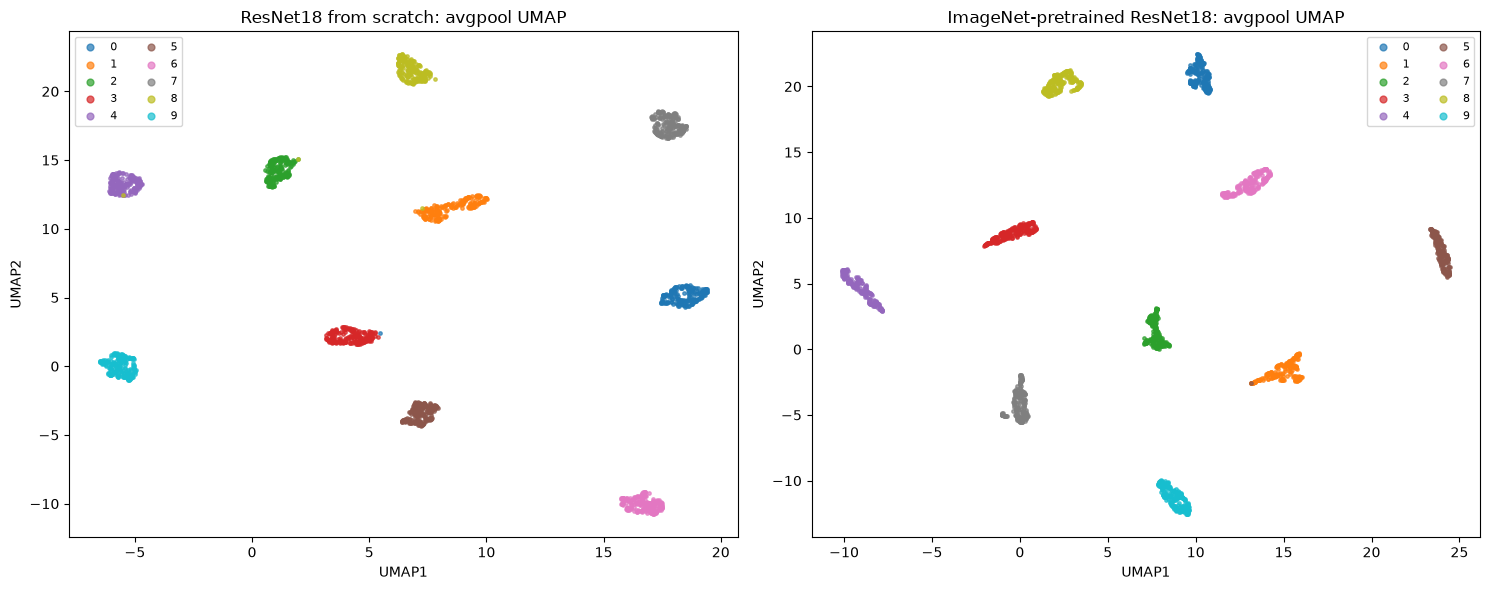

In [ ]:
# Experiment 2

from torchvision import models

# Config
RESNET_IMAGE_SIZE=128
RESNET_TRAIN_PER_CLASS=1000
RESNET_VAL_PER_CLASS=200
RESNET_BATCH_SIZE=64
RESNET_EPOCHS=8
RESNET_LR=1e-3
RESNET_WEIGHT_DECAY=1e-4
RESNET_UMAP_PER_CLASS=200

# Dataset preparations (same images and preprocessing for both versions)
resnet_transform = transforms.Compose([
    transforms.Resize((RESNET_IMAGE_SIZE, RESNET_IMAGE_SIZE)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])
resnet_mnist = datasets.MNIST(root="./data", train=True, download=True, transform=resnet_transform)
resnet_rng = np.random.default_rng(SEED)
resnet_targets = np.asarray(resnet_mnist.targets)
resnet_train_ids, resnet_val_ids = [], []

for cls in range(10):
  ids = resnet_rng.permutation(np.flatnonzero(resnet_targets == cls))
  count = RESNET_TRAIN_PER_CLASS + RESNET_VAL_PER_CLASS
  assert len(ids) >= count, f"Not enough images of class {cls}"
  resnet_train_ids.extend(ids[:RESNET_TRAIN_PER_CLASS].tolist())
  resnet_val_ids.extend(ids[RESNET_TRAIN_PER_CLASS:count].tolist())

resnet_train_dataset = Subset(resnet_mnist, resnet_train_ids)
resnet_val_dataset = Subset(resnet_mnist, resnet_val_ids)
resnet_pin = (device.type == "cuda")

# Non-shuffled loaders for full dataset metrics
resnet_train_eval_loader = DataLoader(resnet_train_dataset, batch_size=RESNET_BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=resnet_pin)
resnet_val_loader = DataLoader(resnet_val_dataset, batch_size=RESNET_BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=resnet_pin)

# Network and evaluation
def make_resnet18(pretrained):
  weights = models.ResNet18_Weights.DEFAULT if pretrained else None
  net = models.resnet18(weights=weights)
  net.fc = nn.Linear(net.fc.in_features, 10)
  return net.to(device)

# This line prevents PyTorch from doing graph computations during training,
# saving on computing time
@torch.inference_mode()
def evaluate_resnet(net, loader):
  net.eval()
  total_loss, correct, n = 0.0, 0, 0
  loss_fn = nn.CrossEntropyLoss()
  for xb, yb in loader:
    xb = xb.to(device, non_blocking=True)
    yb = yb.to(device, non_blocking=True)
    with torch.autocast(device_type=device.type, enabled=(device.type == "cuda")):
      logits = net(xb)
      loss = loss_fn(logits, yb)
    total_loss += loss.item() * len(yb)
    correct += (logits.argmax(dim=1) == yb).sum().item()
    n += len(yb)
  return total_loss / n, correct / n

def train_resnet18(pretrained):
  net = make_resnet18(pretrained)
  shuffle_rng = torch.Generator().manual_seed(SEED)
  train_loader = DataLoader(resnet_train_dataset, batch_size=RESNET_BATCH_SIZE, shuffle=True, generator=shuffle_rng, num_workers=2, pin_memory=resnet_pin)
  optimizer = torch.optim.AdamW(net.parameters(), lr=RESNET_LR, weight_decay=RESNET_WEIGHT_DECAY)
  scaler = torch.amp.GradScaler("cuda", enabled=(device.type == "cuda"))
  loss_fn = nn.CrossEntropyLoss()
  hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "batch_loss": []}
  # Include epoch 0 to compare initial losses
  for epoch in range(RESNET_EPOCHS + 1):
    if epoch > 0:
      net.train()
      for xb, yb in train_loader:
        xb = xb.to(device, non_blocking=True)
        yb = yb.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, enabled=(device.type=="cuda")):
          logits = net(xb)
          loss = loss_fn(logits, yb)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        hist["batch_loss"].append(loss.item())
    train_loss, train_acc = evaluate_resnet(net, resnet_train_eval_loader)
    val_loss, val_acc = evaluate_resnet(net, resnet_val_loader)
    hist["train_loss"].append(train_loss)
    hist["train_acc"].append(train_acc)
    hist["val_loss"].append(val_loss)
    hist["val_acc"].append(val_acc)
    print(f"{'ImageNet' if pretrained else 'Random':8s} | "
          f"Epoch {epoch:02d} |"
          f"train loss {train_loss:.4f}, acc {train_acc:.2%} |"
          f"val loss {val_loss:.4f}, acc {val_acc:.2%}")
  return net, hist

resnet_random_model, resnet_random_hist = train_resnet18(pretrained=False)
resnet_pretrained_model, resnet_pretrained_hist = train_resnet18(pretrained=True)

# Loss and accuracy curves
resnet_epochs = np.arange(RESNET_EPOCHS + 1)
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for hist, label in [(resnet_random_hist, "Random initialization"), (resnet_pretrained_hist, "ImageNet pretraining")]:
  for ax, field in [(axes[0, 0], "train_loss"), (axes[0,1], "val_loss"), (axes[1, 0], "train_acc"), (axes[1, 1], "val_acc")]:
    ax.plot(resnet_epochs, hist[field], marker="o", label=label)
for ax, title in zip(axes.flat, ["Train loss", "Validation loss", "Train accuracy", "Validation accuracy"]):
  ax.set_title(title)
  ax.set_xlabel("Epoch")
  ax.set_ylabel("Accuracy" if "accuracy" in title.lower() else "Cross-entropy")
  ax.grid(alpha=0.3)
  ax.legend()
plt.tight_layout()
plt.show()

# Loss by iteration (smoothed to reduce per-batch noise)
plt.figure(figsize=(10, 4))
for hist, label in [(resnet_random_hist, "Random initialization"), (resnet_pretrained_hist, "ImageNet pretraining")]:
  losses = np.asarray(hist["batch_loss"])
  window = min(20, len(losses))
  smoothed = np.convolve(losses, np.ones(window) / window, mode="valid")
  plt.plot(np.arange(window - 1, len(losses)), smoothed, label=label)
plt.xlabel("Optimizer iteration")
plt.ylabel("Cross-entropy (moving average)")
plt.title("Training loss by iteration")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Pre-flatten extraction for UMAP
resnet_local_labels = resnet_targets[resnet_train_ids]
resnet_umap_rng = np.random.default_rng(SEED)
resnet_umap_ids = []
for cls in range(10):
  candidates = np.flatnonzero(resnet_local_labels == cls)
  selected = resnet_umap_rng.choice(candidates, size=RESNET_UMAP_PER_CLASS, replace=False)
  resnet_umap_ids.extend(selected.tolist())
resnet_umap_rng.shuffle(resnet_umap_ids)
resnet_umap_loader = DataLoader(Subset(resnet_train_dataset, resnet_umap_ids), batch_size=RESNET_BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=resnet_pin)

# This line prevents PyTorch from doing graph computations during training,
# saving on computing time
@torch.inference_mode()
def resnet_avgpool_features(net, loader):
  net.eval()
  # We want the features just before the flatten
  # Since Resnet's final module is fc, the one right before it is avgpool
  # and is the one we're interested in
  extractor = nn.Sequential(*list(net.children())[:-1])
  extractor.eval()
  features, targets = [], []
  for xb, yb in loader:
    xb = xb.to(device, non_blocking=True)
    pooled = extractor(xb)
    features.append(pooled.flatten(1).cpu().numpy())
    targets.append(yb.numpy())
  return (np.concatenate(features).astype(np.float32), np.concatenate(targets))

# Extract features...
resnet_features_random, resnet_labels_random = resnet_avgpool_features(resnet_random_model, resnet_umap_loader)
resnet_features_pretrained, resnet_labels_pretrained = resnet_avgpool_features(resnet_pretrained_model, resnet_umap_loader)
assert np.array_equal(resnet_labels_random, resnet_labels_pretrained)
print("Features before flatten:", resnet_features_random.shape, resnet_features_pretrained.shape)

# ...and project them
resnet_umap_random = run_umap(resnet_features_random, seed=SEED)
resnet_umap_pretrained = run_umap(resnet_features_pretrained, seed=SEED)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
plot_umap(resnet_umap_random, resnet_labels_random, mnist_names, "ResNet18 from scratch: avgpool UMAP", axes[0])
plot_umap(resnet_umap_pretrained, resnet_labels_pretrained, mnist_names,"ImageNet-pretrained ResNet18: avgpool UMAP", axes[1])
plt.tight_layout()
plt.show()

# Expérience 2

L'intérêt d'un réseau pré-entraîné est qu'il a déjà appris certaines formes ou représentations visuelles qui peuvent être appliquées à d'autres tâches. Par exemple, ResNet18 avec les poids d'entraînement sur ImageNet sait déjà reconnaître les bords, les contours, certaines formes etc. Ainsi, le modèle peut simplement adapter ce qu'il a déjà à la nouvelle tâche (ici, les données MNIST). De manière générale, cela entraîne une convergence plus rapide vers une bonne valeur de la fonction de coût, un temps d'entraînement réduit et une meilleure généralisation (d'autant plus que le nouveau jeu de données est relativement petit: le modèle a moins de nouvelles choses à apprendre).

On peut donc observer que le réseau pré-entraîné commence effectivement avec une meilleure loss et une meilleure précision pendant les premières époques. On voit donc tout l'intérêt d'un réseau pré-entraîné. Malgré cela, la différence entre ce réseau et le réseau "frais" est relativement petite. Les deux réseaux convergent assez vite, et atteignent une accuracy d'entraînement quasi parfaite ainsi qu'une excellente accuracy de validation après quelques époques.

Pour ce qui est des projections UMAP, les deux modèles ont une représentation très séparée des classes: chaque classe forme un cluster isolé des autres. Les représentations apprises par le modèle des données permettent ainsi de beaucoup mieux classer les exemples. Les exemples appartenant à la même classe sont fortement associés dans la représentation du modèle, d'où ces clusters dans la projection UMAP.